# CNN Klassifikatoren mit Keras

In [4]:
import kagglehub
import pandas as pd
import os
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

c:\Users\Admin\miniconda3\envs\dermascan312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
dataset_path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", dataset_path)

metadata_file = os.path.join(dataset_path, "HAM10000_metadata.csv")
df = pd.read_csv(metadata_file)

Path to dataset files: C:\Users\Admin\.cache\kagglehub\datasets\kmader\skin-cancer-mnist-ham10000\versions\2


**Datensatz um vollständigen medizinischen Namen erweitern**

In [6]:
lesion_type_dict = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions ',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}


imageid_path_dict = {os.path.splitext(os.path.basename(x))[0]: x
                     for x in glob(os.path.join(dataset_path, '*', '*.jpg'))}


df['path'] = df['image_id'].map(imageid_path_dict.get)
df['cell_type'] = df['dx'].map(lesion_type_dict.get) 
df['cell_type_idx'] = pd.Categorical(df['cell_type']).codes
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,path,cell_type,cell_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,C:\Users\Admin\.cache\kagglehub\datasets\kmade...,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,C:\Users\Admin\.cache\kagglehub\datasets\kmade...,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,C:\Users\Admin\.cache\kagglehub\datasets\kmade...,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,C:\Users\Admin\.cache\kagglehub\datasets\kmade...,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,C:\Users\Admin\.cache\kagglehub\datasets\kmade...,Benign keratosis-like lesions,2


### Bildvorverarbeitung und Aufteilung

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix


from PIL import Image
from keras.layers import Dropout, Dense, Flatten, MaxPool2D, Conv2D
from keras.models import Sequential
from keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau
from keras.optimizers import Adam

In [8]:
df['image'] = df['path'].map(lambda x: np.asarray(Image.open(x).resize((200, 150))))

In [9]:
print(df.isnull().sum())
df.fillna({'age': (df['age'].mean())}, inplace=True)
print(df.isnull().sum())

features=df.drop(columns=['cell_type_idx'],axis=1)
target=df['cell_type_idx']

lesion_id         0
image_id          0
dx                0
dx_type           0
age              57
sex               0
localization      0
path              0
cell_type         0
cell_type_idx     0
image             0
dtype: int64
lesion_id        0
image_id         0
dx               0
dx_type          0
age              0
sex              0
localization     0
path             0
cell_type        0
cell_type_idx    0
image            0
dtype: int64


In [10]:
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size = 0.1, random_state = 42)

In [11]:
x_train = np.asarray(x_train['image'].tolist())
x_test = np.asarray(x_test['image'].tolist())

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [12]:
y_train = to_categorical(y_train, num_classes = 7)
y_test = to_categorical(y_test, num_classes = 7)

In [13]:
x_train, x_validate, y_train, y_validate = train_test_split(x_train, y_train, test_size = 0.1, random_state = 999)

# Reshape image in 3 dimensions (height = 200, width = 125 , canal = 3)
x_train = x_train.reshape(x_train.shape[0], *(150, 200, 3))
x_test = x_test.reshape(x_test.shape[0], *(150, 200, 3))
x_validate = x_validate.reshape(x_validate.shape[0], *(150, 200, 3))

In [14]:
input_shape = (150, 200, 3)
num_classes = 7

model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3),activation='relu',padding = 'Same',input_shape=input_shape))
model.add(Conv2D(32,kernel_size=(3, 3), activation='relu',padding = 'Same',))
model.add(MaxPool2D(pool_size = (2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), activation='relu',padding = 'Same'))
model.add(Conv2D(64, (3, 3), activation='relu',padding = 'Same'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Dropout(0.40))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))
model.summary()

c:\Users\Admin\miniconda3\envs\dermascan312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 200, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 200, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 100, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 100, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 100, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 100, 64)    │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 37, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 118400)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    15,155,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,221,799 (58.07 MB)

 Trainable params: 15,221,799 (58.07 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
optimizer = Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, amsgrad=False)

In [16]:
model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])

In [17]:
learning_rate_reduction = ReduceLROnPlateau(
    monitor='val_accuracy',
    patience=3,
    verbose=1,
    factor=0.5,
    min_lr=1e-5
)

In [18]:
print("Checking for null values in training and validation data:")
print(f"x_train null values: {np.isnan(x_train).sum()}")
print(f"y_train null values: {np.isnan(y_train).sum()}")
print(f"x_validate null values: {np.isnan(x_validate).sum()}")
print(f"y_validate null values: {np.isnan(y_validate).sum()}")

print("\nData shapes:")
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_validate shape: {x_validate.shape}")
print(f"y_validate shape: {y_validate.shape}")

Checking for null values in training and validation data:
x_train null values: 0
y_train null values: 0
x_validate null values: 0
y_validate null values: 0

Data shapes:
x_train shape: (8111, 150, 200, 3)
y_train shape: (8111, 7)
x_validate shape: (902, 150, 200, 3)
y_validate shape: (902, 7)


In [19]:
epochs = 50
batch_size = 10

history = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_validate, y_validate),
    verbose=1,
    callbacks=[learning_rate_reduction]
)

Epoch 1/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 332s 406ms/step - accuracy: 0.6717 - loss: 1.0794 - val_accuracy: 0.6585 - val_loss: 0.9713 - learning_rate: 0.0010
Epoch 2/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 328s 404ms/step - accuracy: 0.6734 - loss: 0.9673 - val_accuracy: 0.6585 - val_loss: 0.9498 - learning_rate: 0.0010
Epoch 3/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 326s 401ms/step - accuracy: 0.6746 - loss: 0.9420 - val_accuracy: 0.6630 - val_loss: 0.9079 - learning_rate: 0.0010
Epoch 4/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 301s 370ms/step - accuracy: 0.6834 - loss: 0.8973 - val_accuracy: 0.6663 - val_loss: 0.9198 - learning_rate: 0.0010
Epoch 5/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 285s 351ms/step - accuracy: 0.6806 - loss: 0.9126 - val_accuracy: 0.6729 - val_loss: 0.8848 - learning_rate: 0.0010
Epoch 6/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 286s 352ms/step - accuracy: 0.6892 - loss: 0.8565 - val_accuracy: 0.6741 - val_loss: 0.8849 - learning_rate: 0.0010
Epoch 7/50
812/812 ━━━━━━━━━━━━━━━━━━━━ 284s 349ms/step - accura

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f  ;  loss_v = %f" % (accuracy_v, loss_v))
print("Test: accuracy = %f  ;  loss = %f" % (accuracy, loss))
model.save("../models/model.keras")

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 196ms/step - accuracy: 0.7026 - loss: 1.3354
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.7007 - loss: 1.4659


Validation: accuracy = 0.700665  ;  loss_v = 1.465918
Test: accuracy = 0.702595  ;  loss = 1.335444


In [33]:
def plot_model_history(model_history):
    fig, axs = plt.subplots(1,2,figsize=(15,5))

    epochs = len(model_history.history['accuracy'])
    step = max(1, epochs // 5)

    axs[0].plot(range(1, epochs+1), model_history.history['accuracy'])
    axs[0].plot(range(1, epochs+1), model_history.history['val_accuracy'])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    axs[0].set_xticks(np.arange(1, epochs+1, step))
    axs[0].legend(['train', 'val'], loc='best')

    axs[1].plot(range(1, epochs+1), model_history.history['loss'])
    axs[1].plot(range(1, epochs+1), model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    axs[1].set_xticks(np.arange(1, epochs+1, step))
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()

In [26]:
import itertools
# Function to plot confusion matrix    
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

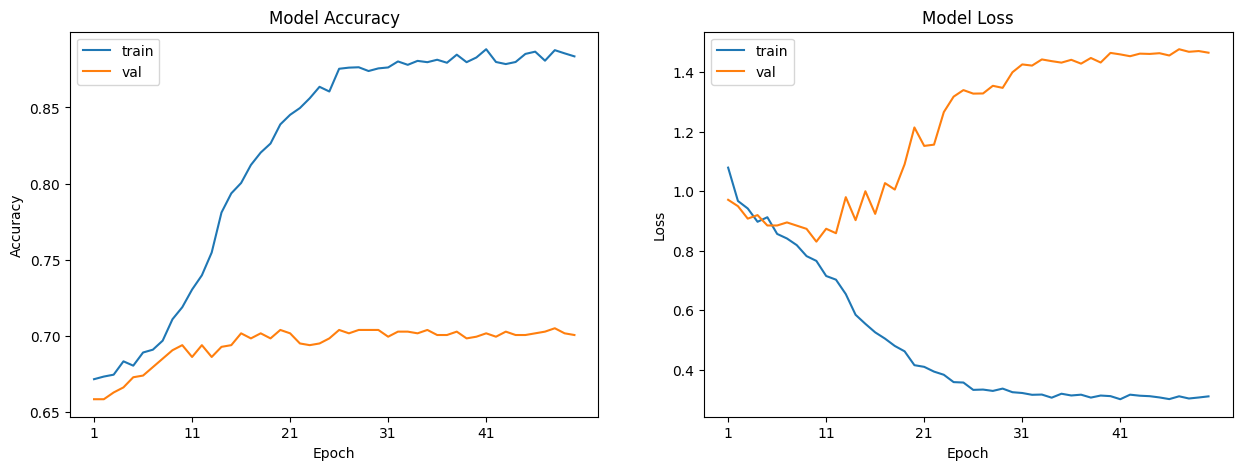

In [34]:
plot_model_history(history)

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step


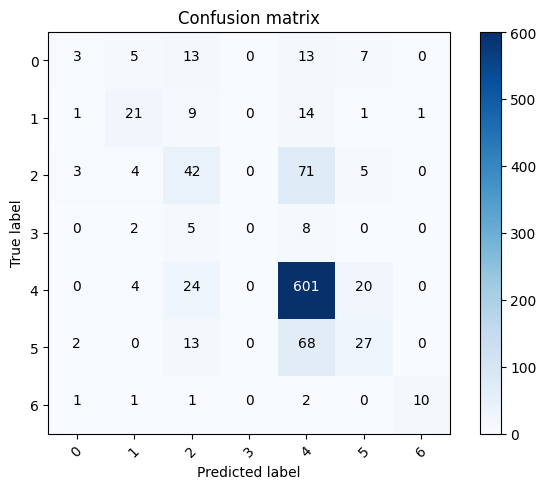

In [30]:
# Predict the values from the validation dataset
Y_pred = model.predict(x_test)
# Convert predictions classes to one hot vectors 
Y_pred_classes = np.argmax(Y_pred,axis = 1) 
# Convert validation observations to one hot vectors
Y_true = np.argmax(y_test,axis = 1) 
# compute the confusion matrix
confusion_mtx = confusion_matrix(Y_true, Y_pred_classes)

 
# plot the confusion matrix
plot_confusion_matrix(confusion_mtx, classes = range(7)) 